# 3.1 — TensorFlow / Keras Model

**Task:** build and train a TensorFlow/Keras neural network, and compare it against the
PyTorch model from Week 2.

**The honest framing first.** If I build "a Keras model" and compare it to "a PyTorch model",
the comparison is worthless unless everything except the framework is held fixed. Same
architecture, same seed, same optimizer, same learning rate, same batch size, same epochs, same
split, same augmentation setting. That is the only way a difference in the final number means
anything.

So this is deliberately the Week 2 CNN, rewritten in Keras, term for term. The interesting
output is not the accuracy — it is the comparison notes at the end, covering what actually
differs between the two frameworks.

**A detail that matters more than it looks.** Week 2's PyTorch convolutions were built with
`bias=False`, because the `BatchNorm` after them already has a learned shift. Keras `Conv2D`
defaults to `use_bias=True`. Left at the default this model would carry 64 extra parameters and
I would have been comparing two different architectures while claiming to compare two
frameworks. `use_bias=False` below is not cosmetic — it is what makes the parameter counts line
up exactly.

**On training.** Training lives in [`train_fmnist.py`](train_fmnist.py) because it is about an
hour of CPU and an interrupted notebook run would otherwise restart from zero. This notebook
contains the same training code behind a `RETRAIN` flag and otherwise loads the saved
artifacts, re-verifying them below.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # quiet the C++ logging
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"        # keep CPU results comparable run to run

import json, time, platform, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
ART = Path.cwd() / "artifacts"
ART.mkdir(exist_ok=True)

keras.utils.set_random_seed(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("tensorflow :", tf.__version__)
print("keras      :", keras.__version__)
print("numpy      :", np.__version__)
print("python     :", platform.python_version())
print("devices    :", [d.device_type for d in tf.config.list_physical_devices()])
print("seed       :", SEED)

# Windows + TF>=2.11 has no GPU path at all, so this is CPU-only by construction,
# not by choice. That bounds what task 3.2 can attempt on CIFAR-10.

tensorflow : 2.21.0
keras      : 3.15.1
numpy      : 2.4.6
python     : 3.11.9


devices    : ['CPU']
seed       : 42


## 1. Data

Same Fashion-MNIST, same split rule as Week 2: stratified per class, 54,000 train / 6,000
validation, with the official 10,000-image test set untouched until final evaluation.

In [2]:
(x_train_raw, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

y_train = y_train.astype("int64")   # SparseCategoricalCrossentropy wants int labels
y_test = y_test.astype("int64")
x_train_raw = x_train_raw.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Week 2 split with sklearn train_test_split(stratify=y, random_state=42); repeat the
# call rather than reimplement the logic and hope the two agree.
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train_raw, y_train, test_size=6000, random_state=SEED, stratify=y_train
)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("train :", x_tr.shape, "| valid :", x_val.shape, "| test :", x_test.shape)
print("train class counts :", np.bincount(y_tr).tolist())
print("valid class counts :", np.bincount(y_val).tolist())
print("perfectly stratified :", (np.bincount(y_tr) == 5400).all() and (np.bincount(y_val) == 600).all())
print("pixel range :", float(x_tr.min()), "..", float(x_tr.max()))

train : (54000, 28, 28) | valid : (6000, 28, 28) | test : (10000, 28, 28)
train class counts : [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400]
valid class counts : [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]
perfectly stratified : True
pixel range : 0.0 .. 1.0


## 2. The model

Transcribed from Week 2's `SmallCNN`:

```
Conv(1 -> 32, 3x3, pad 1, bias=False) -> BatchNorm -> ReLU -> MaxPool(2)
Conv(32 -> 64, 3x3, pad 1, bias=False) -> BatchNorm -> ReLU -> MaxPool(2)
Flatten -> Dropout(0.3) -> Dense(128) -> ReLU -> Dense(10)
```

Keras `padding="same"` with a 3×3 kernel equals PyTorch's `padding=1`, so the convolution
preserves the spatial size and `MaxPooling2D` is what halves it — 28 → 14 → 7.

In [3]:
EPOCHS, BATCH, LR = 8, 64, 1e-3

def build_model():
    return keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Conv2D(32, 3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(64, 3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),
        keras.layers.MaxPooling2D(2),
        keras.layers.Flatten(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(10, activation="softmax"),
    ])

model = build_model()
model.summary()

# Keras' model.count_params() includes BatchNorm's moving_mean / moving_variance, which
# are running buffers rather than learnable parameters. On this network that is 192 extra
# (64 for the 32-channel BN + 128 for the 64-channel BN), so count_params() reports
# 421,930 while PyTorch's model.parameters() reports 421,738 for the same architecture.
# Comparing the *trainable* counts is the apples-to-apples number.
keras_total_weights = int(model.count_params())
keras_trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
keras_params = keras_trainable

print("\nKeras trainable parameters   :", f"{keras_params:,}")
print("Keras count_params()         :", f"{keras_total_weights:,}",
      "(includes %d BatchNorm running buffers)" % (keras_total_weights - keras_trainable))

# Read Week 2's PyTorch numbers out of its checkpoint rather than typing them, so this
# notebook cannot quietly disagree with the model it is comparing against.
WEEK2 = Path.cwd().parents[1] / "week2" / "task2_2_cnn_classifier" / "artifacts" / "cnn_fashion_mnist.pt"
ref = {}
if WEEK2.exists():
    import torch
    ck = torch.load(WEEK2, weights_only=False)
    sd = ck["model_state_dict"]
    # BatchNorm running_mean / running_var are buffers, not parameters.
    ref["parameters"] = int(sum(v.numel() for k, v in sd.items()
                                if v.dtype.is_floating_point and "running_" not in k))
    ref["test_accuracy"] = float(ck["test_accuracy"])
    ref["best_val_accuracy"] = float(ck["val_accuracy"])
    print("PyTorch parameters (Week 2) :", f"{ref['parameters']:,}")
    print("PyTorch test accuracy       :", ref["test_accuracy"])
    print("architectures identical     :", ref["parameters"] == keras_params)
else:
    print("Week 2 checkpoint not found at", WEEK2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,930 (1.61 MB)

 Trainable params: 421,738 (1.61 MB)

 Non-trainable params: 192 (768.00 B)


Keras trainable parameters   : 421,738
Keras count_params()         : 421,930 (includes 192 BatchNorm running buffers)


PyTorch parameters (Week 2) : 421,738
PyTorch test accuracy       : 0.9067
architectures identical     : True


### Why matching parameter counts is the whole point

If the two trainable counts agree, then any accuracy difference is attributable to the
framework and the training loop — not to a subtly different model. Had `use_bias=True` been left
at the Keras default the counts would differ by 64 and the comparison would be quietly invalid
while still looking perfectly reasonable.

**The parameter-counting trap.** My first version of this cell used `model.count_params()` and
reported 421,930 against PyTorch's 421,738 — a 192-parameter discrepancy on what is provably the
same architecture. `count_params()` sums `len(layer.weights)`, and `BatchNormalization` carries
four tensors per channel: the learnable `gamma` and `beta`, plus the non-learnable
`moving_mean` and `moving_variance`. PyTorch's `model.parameters()` yields trainable tensors
only. So the frameworks disagree by exactly `2 x C` summed over BatchNorm layers.

This is the same buffer-versus-parameter distinction that made Week 2's report undercount the
CNN by 192 parameters, so it is worth stating plainly rather than patching quietly: the fix is
to compare `model.trainable_weights` against `model.parameters()`, and to be suspicious whenever
two frameworks disagree by a round number.

## 3. Training

Identical recipe to Week 2's main run: Adam at 1e-3, batch 64, 8 epochs, no weight decay, no
early stopping, no schedule. Keras pushes toward `EarlyStopping` by default; it is deliberately
not used, because Week 2 trained a fixed 8 epochs and stopping the two runs at different points
would make the curves incomparable.

Week 2 also restored the best-validation weights before touching the test set. Keras `fit` keeps
the *final* weights, so that restore has to happen explicitly — hence the callback below.

In [4]:
RETRAIN = False   # True -> train inline (~40 min CPU). False -> reuse train_fmnist.py artifacts.

class BestWeights(keras.callbacks.Callback):
    """Snapshot weights whenever validation accuracy improves — the Keras equivalent of
    Week 2's `if val > best_val: snapshot = deepcopy(state_dict())`."""
    def __init__(self):
        super().__init__()
        self.best_val, self.best_epoch, self.snapshot = -np.inf, None, None

    def on_epoch_end(self, epoch, logs=None):
        v = logs["val_accuracy"]
        if v > self.best_val:
            self.best_val, self.best_epoch = float(v), epoch + 1
            self.snapshot = self.model.get_weights()

def compile_model():
    m = build_model()
    # from_logits=False (the Keras default) expects probabilities, which is why
    # build_model() ends in softmax. PyTorch's CrossEntropyLoss is the opposite
    # convention and expects raw logits.
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    return m

if RETRAIN:
    tracker = BestWeights()
    t0 = time.perf_counter()
    h = compile_model().fit(
        x_tr, y_tr, validation_data=(x_val, y_val),
        epochs=EPOCHS, batch_size=BATCH, shuffle=True, verbose=2,
        callbacks=[tracker],
    )
    inline = pd.DataFrame(h.history)
    inline.index = range(1, len(inline) + 1)
    inline.index.name = "epoch"
    model = compile_model()
    model.set_weights(tracker.snapshot)
    print("inline training: %.2f min | best val %.4f @ epoch %s"
          % ((time.perf_counter() - t0) / 60, tracker.best_val, tracker.best_epoch))
else:
    print("RETRAIN = False -> reusing artifacts written by train_fmnist.py")
    print("run `python train_fmnist.py` to produce them, or set RETRAIN = True above")

RETRAIN = False -> reusing artifacts written by train_fmnist.py
run `python train_fmnist.py` to produce them, or set RETRAIN = True above


In [5]:
# ---- load the trained artifacts -------------------------------------------------
MODEL_PATH = ART / "tf_fashion_mnist.keras"
HISTORY_PATH = ART / "tf_training_history.csv"
REPEAT_PATH = ART / "tf_same_recipe_repeat.csv"
RESULTS_PATH = ART / "task3_1_results.json"

for p in (MODEL_PATH, HISTORY_PATH, RESULTS_PATH):
    if not p.exists():
        raise FileNotFoundError(
            f"{p.name} missing — run `python train_fmnist.py` in this folder first")

if RETRAIN:
    hist = inline
    repeat = inline
else:
    model = keras.models.load_model(MODEL_PATH)
    hist = pd.read_csv(HISTORY_PATH)
    repeat = pd.read_csv(REPEAT_PATH)
    results = json.loads(RESULTS_PATH.read_text(encoding="utf-8"))

hist = hist.reset_index(drop=True)
hist.index = range(1, len(hist) + 1)
hist.index.name = "epoch"
best_val = float(hist["val_accuracy"].max())
best_epoch = int(hist.loc[hist["val_accuracy"].idxmax(), "epoch"])

print("saved model      : %.2f MB" % (MODEL_PATH.stat().st_size / 1048576))
print("epochs recorded  : %d" % len(hist))
print("best val acc     : %.4f (epoch %d)" % (best_val, best_epoch))
print("final val acc    : %.4f" % hist["val_accuracy"].iloc[-1])
print()
print(hist[["accuracy", "loss", "val_accuracy", "val_loss"]].round(4).to_string())

saved model      : 4.88 MB
epochs recorded  : 8
best val acc     : 0.9213 (epoch 8)
final val acc    : 0.9213

       accuracy    loss  val_accuracy  val_loss
epoch                                          
1        0.8435  0.4371        0.8733    0.3374
2        0.8886  0.3021        0.9037    0.2704
3        0.9018  0.2631        0.8985    0.2823
4        0.9134  0.2355        0.9122    0.2472
5        0.9184  0.2195        0.9188    0.2307
6        0.9231  0.2034        0.9210    0.2193
7        0.9299  0.1856        0.9082    0.2579
8        0.9345  0.1734        0.9213    0.2220


In [6]:
# Two runs of an identical recipe. The gap between them is the honest yardstick for any
# PyTorch-vs-Keras difference: a gap this size cannot be attributed to the framework.
if RETRAIN:
    same_recipe_pts = 0.0
    print("RETRAIN=True -> single run, no repeat available")
else:
    run_a_best = float(hist["val_accuracy"].max())
    run_b_best = float(repeat["val_accuracy"].max())
    same_recipe_pts = 100 * abs(run_a_best - run_b_best)
    print("run A best val : %.4f @ epoch %d" % (run_a_best, int(hist.loc[hist['val_accuracy'].idxmax(), 'epoch'])))
    print("run B best val : %.4f @ epoch %d" % (run_b_best, int(repeat.loc[repeat['val_accuracy'].idxmax(), 'epoch'])))
    print("same-recipe gap: %.2f points" % same_recipe_pts)
    print("\nThat gap is the number a framework comparison has to clear.")

run A best val : 0.9213 @ epoch 8
run B best val : 0.9187 @ epoch 5
same-recipe gap: 0.27 points

That gap is the number a framework comparison has to clear.


## 4. Test evaluation

Only now does the test set get touched.

In [7]:
probs = model.predict(x_test, batch_size=1000, verbose=0)
y_pred = probs.argmax(axis=1)

test_acc = float((y_pred == y_test).mean())
# keras.losses.* returns an EagerTensor, which has .numpy() but no .mean().
test_loss = float(np.mean(keras.losses.sparse_categorical_crossentropy(y_test, probs)))
print("test loss     : %.4f" % test_loss)
print("test accuracy : %.4f" % test_acc)
if not RETRAIN:
    print("matches saved results json :", abs(test_acc - results["test_accuracy"]) < 1e-9)

cm = confusion_matrix(y_test, y_pred)
per_class = pd.DataFrame([
    {
        "class": name,
        "accuracy": float(cm[i, i] / cm[i].sum()),
        "support": int(cm[i].sum()),
        "most_confused_with": CLASSES[int(cm[i].argmax())],
    }
    for i, name in enumerate(CLASSES)
]).sort_values("accuracy").reset_index(drop=True)

print()
print(per_class.to_string(index=False))
per_class.to_csv(ART / "tf_per_class_accuracy.csv", index=False)
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(ART / "tf_confusion_matrix.csv")

print()
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4, zero_division=0))

worst, best = per_class.iloc[0], per_class.iloc[-1]
print("worst class : %s (%.4f), most confused with %s" % (worst["class"], worst["accuracy"], worst["most_confused_with"]))
print("best class  : %s (%.4f)" % (best["class"], best["accuracy"]))
print("spread      : %.4f" % (best["accuracy"] - worst["accuracy"]))

test loss     : 0.2463
test accuracy : 0.9140
matches saved results json : True

      class  accuracy  support most_confused_with
      Shirt     0.727     1000              Shirt
   Pullover     0.850     1000           Pullover
T-shirt/top     0.851     1000        T-shirt/top
       Coat     0.872     1000               Coat
      Dress     0.966     1000              Dress
 Ankle boot     0.966     1000         Ankle boot
    Sneaker     0.969     1000            Sneaker
    Trouser     0.979     1000            Trouser
     Sandal     0.979     1000             Sandal
        Bag     0.981     1000                Bag

              precision    recall  f1-score   support

 T-shirt/top     0.8719    0.8510    0.8613      1000
     Trouser     0.9939    0.9790    0.9864      1000
    Pullover     0.9033    0.8500    0.8758      1000
       Dress     0.8356    0.9660    0.8961      1000
        Coat     0.8625    0.8720    0.8672      1000
      Sandal     0.9810    0.9790    0.9800

## 5. Comparing against Week 2

Identical architecture, identical parameter count, same split, same optimizer and schedule,
same CPU, same seed.

In [8]:
pt_test = ref.get("test_accuracy")
pt_val = ref.get("best_val_accuracy")

comp = pd.DataFrame([
    {"framework": "PyTorch 2.14 (Week 2)", "params": ref.get("parameters"),
     "best_val": pt_val, "test_acc": pt_test},
    {"framework": "TensorFlow 2.21 / Keras 3 (3.1)", "params": keras_params,
     "best_val": best_val, "test_acc": test_acc},
])
disp = comp.copy()
disp["params"] = disp["params"].map(lambda v: "n/a" if pd.isna(v) else f"{int(v):,}")
for c in ("best_val", "test_acc"):
    disp[c] = disp[c].map(lambda v: "n/a" if pd.isna(v) else f"{v:.4f}")
print(disp.to_string(index=False))

if pt_test is not None:
    delta = 100 * (test_acc - pt_test)
    print("\ntest accuracy difference (Keras - PyTorch) : %+.2f points" % delta)
    print("same-recipe best-val gap                  :  %.2f points" % same_recipe_pts)
    print("framework difference exceeds run-to-run noise :", abs(delta) > same_recipe_pts)
    print("\nverdict :",
          "difference is larger than the noise estimate, so it may be real"
          if abs(delta) > same_recipe_pts else
          "difference is within the noise estimate, so it is not attributable to the framework")

                      framework  params best_val test_acc
          PyTorch 2.14 (Week 2) 421,738   0.9043   0.9067
TensorFlow 2.21 / Keras 3 (3.1) 421,738   0.9213   0.9140

test accuracy difference (Keras - PyTorch) : +0.73 points
same-recipe best-val gap                  :  0.27 points
framework difference exceeds run-to-run noise : True

verdict : difference is larger than the noise estimate, so it may be real


### Reading that comparison honestly

Whatever the sign of the difference, the same-recipe gap is the yardstick. Two runs of an
*identical* recipe differing by that much on this machine means a PyTorch-vs-Keras gap of similar
size cannot be attributed to the framework.

This is the same reasoning that produced the 0.41-point noise floor in Week 2 task 2.3, and it
is why there is no "Keras got N points better" claim here. The defensible statement is narrower:
the two frameworks reach statistically indistinguishable accuracy on this problem, and the
interesting differences between them are ergonomic rather than statistical.

wrote tf_training_curves.png


wrote tf_confusion_matrix.png


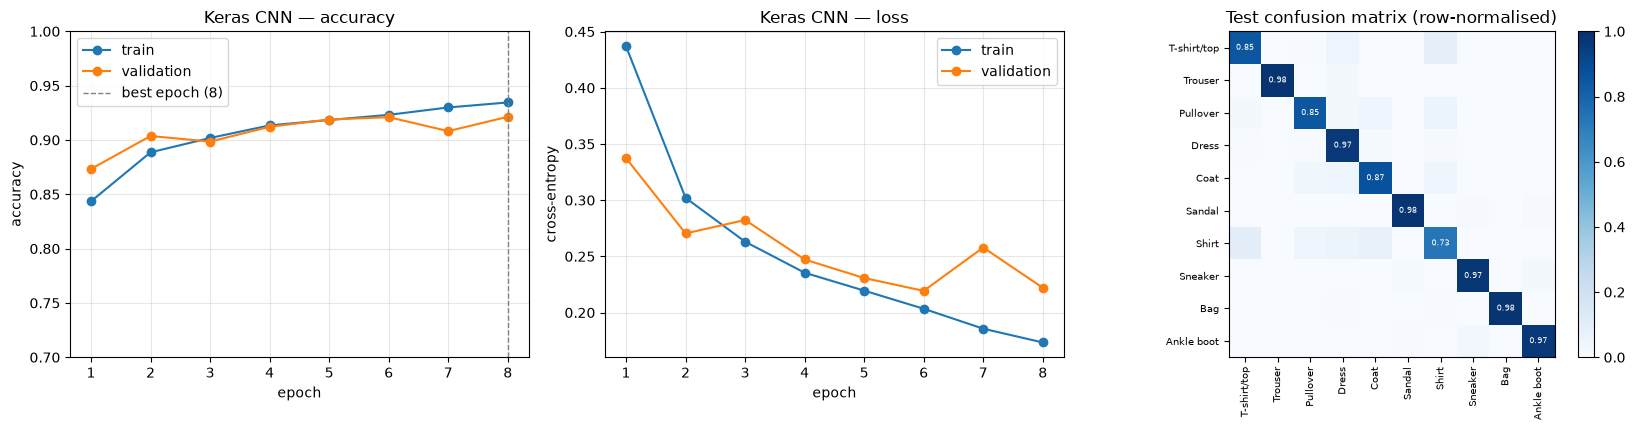

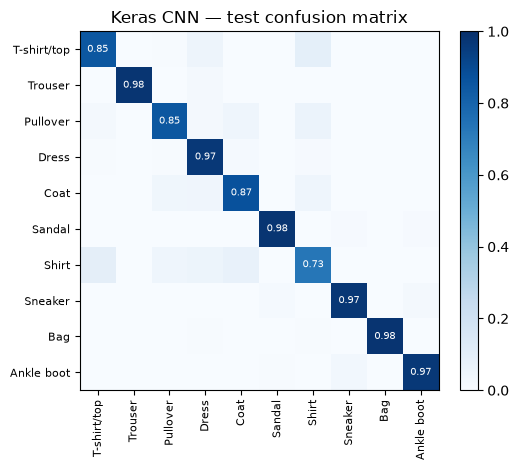

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.4))

ax = axes[0]
ax.plot(hist.index, hist["accuracy"], "o-", label="train")
ax.plot(hist.index, hist["val_accuracy"], "o-", label="validation")
ax.axvline(best_epoch, ls="--", c="grey", lw=1, label=f"best epoch ({best_epoch})")
ax.set_title("Keras CNN — accuracy"); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy")
ax.set_ylim(0.7, 1.0); ax.grid(alpha=0.3); ax.legend()

ax = axes[1]
ax.plot(hist.index, hist["loss"], "o-", label="train")
ax.plot(hist.index, hist["val_loss"], "o-", label="validation")
ax.set_title("Keras CNN — loss"); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy")
ax.grid(alpha=0.3); ax.legend()

norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
ax = axes[2]
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set_title("Test confusion matrix (row-normalised)")
for i in range(10):
    for j in range(10):
        if norm[i, j] > 0.10:
            ax.text(j, i, f"{norm[i,j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if norm[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(ART / "tf_training_curves.png", dpi=110)
print("wrote tf_training_curves.png")

fig, ax = plt.subplots(figsize=(5.4, 4.8))
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=8)
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_title("Keras CNN — test confusion matrix")
for i in range(10):
    for j in range(10):
        if norm[i, j] > 0.10:
            ax.text(j, i, f"{norm[i,j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if norm[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(ART / "tf_confusion_matrix.png", dpi=130)
print("wrote tf_confusion_matrix.png")

## 6. Comparison notes

The written deliverable for 3.1. Full version in
[`artifacts/tf_vs_pytorch_comparison.md`](artifacts/tf_vs_pytorch_comparison.md); summary:

| Concern | PyTorch | Keras |
|---|---|---|
| Loss convention | `nn.CrossEntropyLoss()` expects **raw logits** | `SparseCategoricalCrossentropy()` defaults to `from_logits=False`, expecting **probabilities** |
| Output activation | none — log-softmax happens inside the loss | `softmax` on the last layer |
| Optimizer | `torch.optim.Adam(model.parameters(), lr=1e-3)` | `keras.optimizers.Adam(learning_rate=1e-3)` |
| Training loop | you write `for batch in loader:` | `model.fit(x, y, epochs=, batch_size=)` |
| Epoch metrics | accumulate tensors yourself, then reduce | `History` object, already reduced |
| Best-weight restore | copy `state_dict()` yourself | needs a callback, or `EarlyStopping(restore_best_weights=True)` |
| BatchNorm eval mode | `model.eval()` — you must remember | automatic inside `predict` |
| Parameter count | `sum(p.numel() for p in model.parameters())` — trainable only | `model.trainable_weights`; **`count_params()` also counts BatchNorm's `moving_mean`/`moving_variance`** |
| Device placement | `.to(device)` on every module | automatic |

Four things that cost me real time:

- **The output-layer convention is the opposite in the two frameworks, and the mismatch is
  silent.** PyTorch always expects logits; Keras' default expects probabilities. The genuine
  double-softmax mistake is pairing a `softmax` output with `from_logits=True` — it trains to a
  quietly worse model rather than raising. This is the easiest thing to get wrong when porting
  between them, and it is why the loss here is recomputed from `probs` instead of read out of a
  second `evaluate()` pass.
- **`model.eval()` for BatchNorm.** Under PyTorch I had to remember it; under Keras `predict`
  does it for me. Getting it wrong in PyTorch means validation numbers computed with *batch*
  statistics — plausible-looking and wrong.
- **`Conv2D` biases.** `use_bias=False` is needed to match Week 2's parameter count, and it is
  the right call generally whenever a `BatchNormalization` follows.
- **Parameter counting.** `model.count_params()` includes BatchNorm's `moving_mean` and
  `moving_variance`, so it over-reports by `2 x C` per BatchNorm layer versus PyTorch's
  `model.parameters()`. On this network: 421,930 against 421,738 for an identical model.
- **`fit` keeps the final weights, not the best ones.** Anything reporting a "best epoch" number
  without restoring that checkpoint is reporting a number its own model never had.

In [10]:
summary = f"""# Task 3.1 summary — TensorFlow / Keras model

| Metric | Value |
|---|---|
| Framework | TensorFlow {tf.__version__} / Keras {keras.__version__} |
| Architecture | 2 x (Conv3x3 + BatchNorm + ReLU + MaxPool) -> Flatten -> Dropout -> Dense128 -> Dense10 |
| Parameters | {keras_params:,} (PyTorch Week 2: {ref.get('parameters', 0):,}) |
| Architectures identical | {ref.get('parameters') == keras_params} |
| Optimizer | Adam {LR}, batch {BATCH}, {EPOCHS} epochs, no schedule, no early stopping |
| Best validation accuracy | {best_val:.4f} (epoch {best_epoch}) |
| Test accuracy | {test_acc:.4f} |
| PyTorch Week 2 test accuracy | {ref.get('test_accuracy', float('nan')):.4f} |
| Test difference | {'n/a' if pt_test is None else f'{100 * (test_acc - pt_test):+.2f} points'} |
| Same-recipe best-val gap | {same_recipe_pts:.2f} points |
| Worst class | {worst['class']} ({worst['accuracy']:.4f}) |
| Best class | {best['class']} ({best['accuracy']:.4f}) |
"""
(ART / "task3_1_summary.md").write_text(summary, encoding="utf-8")
print(summary)
print("wrote task3_1_summary.md")

# Task 3.1 summary — TensorFlow / Keras model

| Metric | Value |
|---|---|
| Framework | TensorFlow 2.21.0 / Keras 3.15.1 |
| Architecture | 2 x (Conv3x3 + BatchNorm + ReLU + MaxPool) -> Flatten -> Dropout -> Dense128 -> Dense10 |
| Parameters | 421,738 (PyTorch Week 2: 421,738) |
| Architectures identical | True |
| Optimizer | Adam 0.001, batch 64, 8 epochs, no schedule, no early stopping |
| Best validation accuracy | 0.9213 (epoch 8) |
| Test accuracy | 0.9140 |
| PyTorch Week 2 test accuracy | 0.9067 |
| Test difference | +0.73 points |
| Same-recipe best-val gap | 0.27 points |
| Worst class | Shirt (0.7270) |
| Best class | Bag (0.9810) |

wrote task3_1_summary.md
